# Experiment 1: PD outcomes and evaluation

When does continued pretraining (CPT) on credit tables improve a tabular foundation model on credit tables it never saw during CPT, when does it change little, and when does it hurt? Every result below compares an adapted model with the original checkpoint of the same base on identical held-out tables and outer folds (primary quantity: AUC change in percentage points (pp); positive always means CPT is better). The notebook moves from single-choice contrasts to the complete 4 × 2 × 2 recipe grid per base (peak learning rate × L2-SP strength × update scope), then to individual tables, probability or error quality, and non-credit retention. The grid is descriptive: an observed maximum is not an independently validated recipe, and section 3 quantifies how much selecting the best recipe would overstate.

## 0. Evidence and scope

Positive effects always mean improvement over the original model. A favourable contrast between two CPT choices can mean less damage; only a positive CPT-versus-original effect is a gain over the starting weights. The predefined reference recipe (all weights, LR 3e-7, L2-SP λ 0.003) was fixed before results were seen, following Real-TabPFN.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('experiment1/03_results_pd')
report = cp.NotebookReport('Experiment 1: PD outcomes and evaluation', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.')

from src.visualize import dashboards as db, choice_effects as ce
from src.visualize import finishing as finish
from src.visualize import prediction_diagnostics as pred
from src.visualize import synthesis as sy, research_views as rv


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Evidence and benchmark eligibility

Each final comparison requires five finite, successful outer folds and paired original predictions. All recipes shown within one model use the same tables across the displayed metrics. Non-credit summaries additionally require all four CPT partitions.

In [2]:
run = cp.load_campaign(1, TRACK)
grid = ce.benchmark_grid(run)
effects = sy.table_effects(run, sy.PRIMARY[TRACK], experiment=1)
report.table('Available evidence', pub.availability(run))
report.add('1. Evidence and benchmark eligibility', cp.coverage_summary(run))

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,Benchmark folds,11715,Project final evaluation


## 2. Which CPT choices help?

Compare L2-SP anchoring with no anchoring, a frozen transformer backbone with all parameters updated, and each larger learning rate with the lowest rate. Match every other setting before averaging within table, then weight tables equally. Keep model identities and metric scales separate; opposite effects must not cancel in a pooled model average.

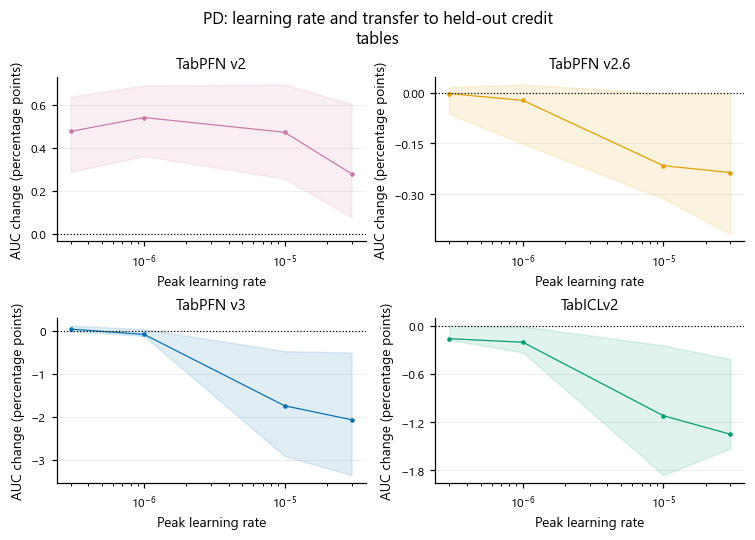

PD. AUC change (percentage points) after 10,000 successful updates, relative to the same original model, on held-out credit tables. All parameters are updated with L2-SP 0.003. Lines show equal-table means; shading is the interquartile range of table effects, not confidence intervals. All learning rates use the same complete table cohort within each base. Positive values favor CPT. Experiments 3 and 4 retain the remaining cells of the shared 512-run factorial and its anchoring/freezing interaction.

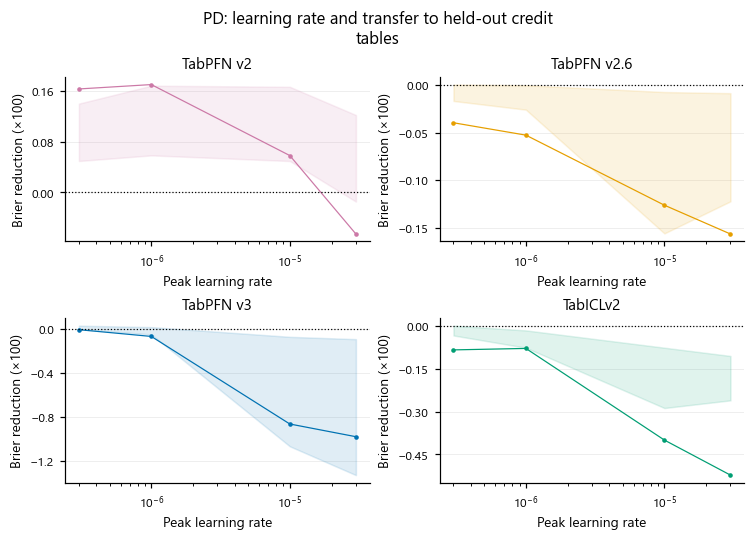

PD. Brier reduction (×100) after 10,000 successful updates, relative to the same original model, on held-out credit tables. All parameters are updated with L2-SP 0.003. Lines show equal-table means; shading is the interquartile range of table effects, not confidence intervals. All learning rates use the same complete table cohort within each base. Positive values favor CPT. Experiments 3 and 4 retain the remaining cells of the shared 512-run factorial and its anchoring/freezing interaction.

In [3]:
cp.show(sink, rv.plot_learning_rates(grid, TRACK), track=TRACK)
report.add('2. Which CPT choices help?', 'The figures show paired effects of peak learning rate while full updates and L2-SP 0.003 stay fixed. Shading describes variation across tables. These descriptive comparisons concern the observed fixed grid; recipe cells and folds are not independent replications.')

## 3. Every recipe against its original model

Average choice effects can hide interactions, and averages over tables can hide heterogeneity. The recipe grid shows every learning-rate × L2-SP × scope combination per base, with the number of tables that improved; peak learning rate is labelled in blue and L2-SP strength in orange throughout. The table maps show which tables carry each mean. The low-rate figure adds medians and table interquartile ranges, and the last figure places credit transfer against non-credit retention. The selection table contrasts the predefined reference with the observed best recipe and with a leave-one-table-out choice, which estimates how much picking the best recipe from this grid overstates its effect.

In [4]:
rate_effects = effects[~effects.frozen & effects.l2sp_lambda.eq(0.003)]
report.table('Full-update anchored recipes: original, CPT and paired effects', sy.summarize(rate_effects))
report.table('Complete factorial source inventory (shared, not additional runs)', run.trials)
report.add('3. Every recipe against its original model', 'E1 isolates learning rate with full updates and L2-SP 0.003. E3/E4 retain all four factorial cells and their interaction. Highest observed scores are not independently validated choices.')

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.785886,-0.011181,...,-0.018589,-0.002421,-0.038751,0.000624,0,2,15,8,85,0.000000
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.783646,0.004731,...,0.002571,0.006950,-0.004872,0.013721,14,1,2,67,85,0.823529
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.790086,-0.002155,...,-0.003128,-0.000013,-0.018340,0.009577,1,7,9,24,85,0.058824
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,roc_auc,17,0.798170,0.780786,-0.017384,...,-0.029074,-0.004695,-0.051384,-0.002197,0,0,17,2,85,0.000000
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.795042,-0.002025,...,-0.003281,-0.000053,-0.008547,0.004457,1,6,10,20,85,0.058824
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.784332,0.005417,...,0.003624,0.006907,0.000125,0.009915,16,1,0,79,85,0.941176
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.792016,-0.000225,...,-0.001505,0.000243,-0.002939,0.006555,2,9,6,29,85,0.117647
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,roc_auc,17,0.798170,0.797360,-0.000810,...,-0.001181,0.000420,-0.005767,0.001205,1,11,5,36,85,0.058824
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.783573,-0.013494,...,-0.015273,-0.004130,-0.052942,-0.000623,0,1,16,8,85,0.000000
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.781716,0.002801,...,0.000787,0.006054,-0.013776,0.010251,12,3,2,65,85,0.705882


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,est_tflops,rows_seen,would_stop_epoch,source_file,source_row,split,attempt_count,evidence_status,base_short,lr_tag
0,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,6,0,1,recorded_only,v2-classifier-v2,3e-07
1,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,7,0,1,recorded_only,v2-classifier-v2,3e-07
2,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,pd,...,1250.615968,84373151,2,cpt_main_v5_s00_pd.csv,4,0,1,recorded_only,v2-classifier-v2,3e-07
3,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,pd,...,1250.615968,84373151,2,cpt_main_v5_s00_pd.csv,5,0,1,recorded_only,v2-classifier-v2,3e-07
4,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,17,0,1,recorded_only,v2-classifier-v2,1e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,pd,...,11259.158116,191675495,12,cpt_main_v5_s03_pd.csv,69,3,2,recorded_only,tabicl-classifier-v2-20260212,1e-05
252,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,pd,...,21124.367695,191675495,17,cpt_main_v5_s03_pd.csv,73,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05
253,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,pd,...,21124.367695,191675495,42,cpt_main_v5_s03_pd.csv,75,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05
254,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,pd,...,11259.158116,191675495,2,cpt_main_v5_s03_pd.csv,72,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05


## 4. The predefined reference, table by table

The reference recipe was fixed in advance, so its effects are not inflated by selection. The first figure shows its paired effect on every held-out table for each base, with fold-level consistency. The second gives table-bootstrap intervals for the mean, conditional on the fitted checkpoints, for all tables and for the subset from documented public sources.

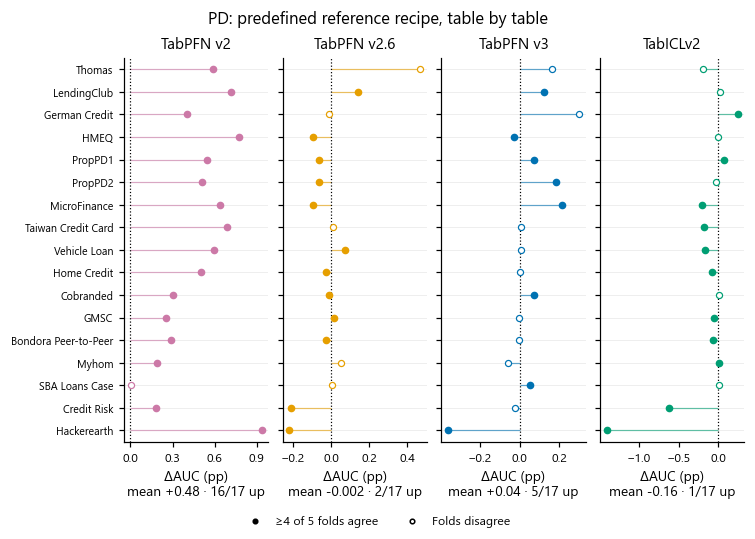

PD. Experiment 1, predefined reference recipe (all trainable weights updated, peak LR 3e-7, L2-SP λ 0.003, seed 42), final five-fold benchmark: paired change in AUC (percentage points) on every held-out credit table relative to the original model of the same base. Each axis label gives the equal-table mean and the number of tables improving by more than 0.1 pp. Filled markers: at least four of the five outer folds change in the direction of the table mean; open markers: the folds disagree. Tables are ordered by their mean effect across the four bases; horizontal axes differ between models. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

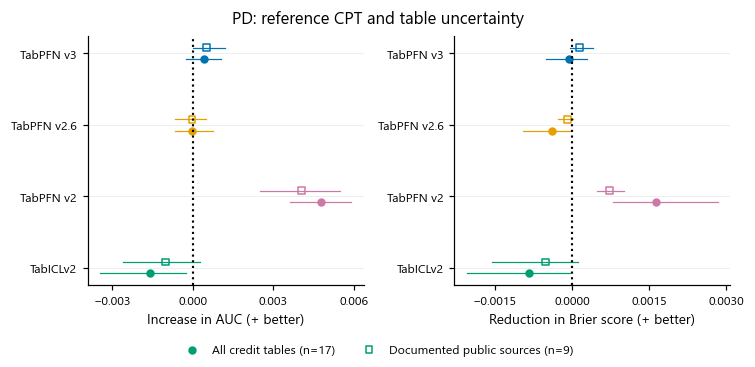

PD. Mean paired benchmark effects of the predefined full-update CPT reference and 95% conditional table-bootstrap intervals. Positive effects favor CPT; RMSE is reported as fractional error reduction. Filled circles include all credit tables; open squares retain documented public sources. Each table contributes the mean of five paired outer folds. Source restriction is based on provenance, not scores. Intervals do not capture training-seed uncertainty or establish source independence.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed,metric
0,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897219,0.896537,-0.000682,-0.000682,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000682,42,roc_auc
1,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.842712,0.842729,0.000016,0.000016,Cobranded,TabICLv2,3.000000e-07,False,0.003,one_sample,0.000016,42,roc_auc
2,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.955257,0.949006,-0.006251,-0.006251,Credit Risk,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.006251,42,roc_auc
3,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.867210,0.866626,-0.000584,-0.000584,GMSC,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000584,42,roc_auc
4,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.790140,0.792556,0.002416,0.002416,German Credit,TabICLv2,3.000000e-07,False,0.003,one_sample,0.002416,42,roc_auc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.229404,0.229532,0.000128,0.000128,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000128,42,f1
404,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.923122,0.929796,0.006675,0.006675,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.006675,42,f1
405,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.548195,0.547957,-0.000238,-0.000238,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.000238,42,f1
406,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.432436,0.442147,0.009711,0.009711,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.009711,42,f1


In [5]:
endpoint = cp.reference_rows(cp.benchmark_effects(run))
cp.show(sink, sy.plot_reference_tables(effects, TRACK), track=TRACK)
cp.show(sink, finish.plot_uncertainty(run), track=TRACK)
report.table('Fixed-reference effects for every table and metric', ce.reference_profiles(run))
report.add('4. The predefined reference, table by table', cp.effect_summary(endpoint) + '\n' + finish.UNCERTAINTY_NOTE + '\n' + finish.SOURCE_NOTE)

## 5. Probability quality and prediction shifts

AUC assesses ranking, while Brier score and log loss assess predictive probabilities. The calibration overview uses the same tables for raw, Platt and isotonic scores; calibration is fitted on inner validation rows, never outer test labels. Saved predictions describe systematic over/underprediction and changes relative to original weights; these are not a theoretical bias-variance decomposition.

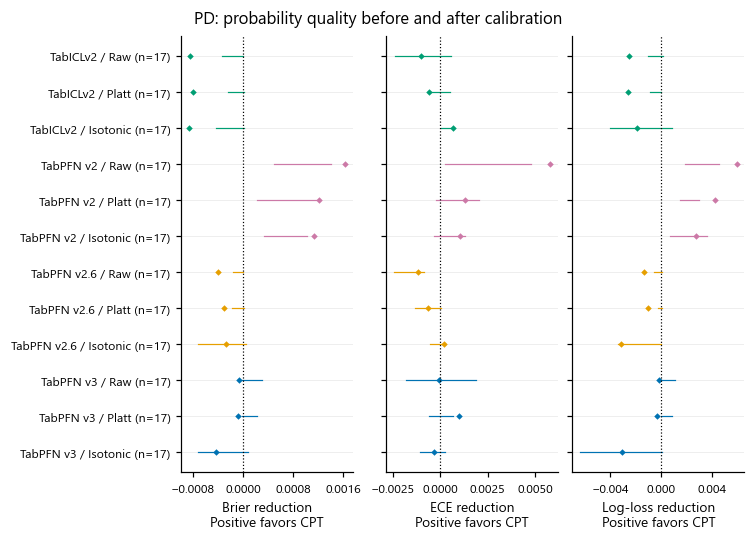

PD. Changes in the displayed outer-test probability-quality scores for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) relative to its untuned base. Positive reductions favor continued pretraining (CPT). Raw probabilities and validation-fitted Platt and isotonic calibration use a common dataset cohort within each base: all 9 scores require the same five completed, matched outer folds. Diamonds show equal-dataset means; horizontal lines span dataset quartiles, not confidence intervals. Log loss, when exported, is in nats; ECE depends on the binning scheme.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
64,TabPFN v3,Cobranded,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
65,TabPFN v3,Home Credit,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
66,TabPFN v3,LendingClub,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,730176,0.138105,0.132381,0.132018,-0.005724,-0.006087,-0.000363,0.080427,0.080659,-0.000232,-0.000363,0.015065,0.007980
1,TabICLv2,HMEQ,0,Reference CPT,5960,0.199497,0.190217,0.191989,-0.009280,-0.007508,0.001772,0.017732,0.018200,-0.000468,0.001772,0.034692,0.011271
2,TabICLv2,MicroFinance,0,Reference CPT,158700,0.378091,0.364455,0.364086,-0.013636,-0.014004,-0.000369,0.217943,0.218420,-0.000477,-0.000369,0.023827,0.018202
3,TabICLv2,Thomas,0,Reference CPT,1225,0.263673,0.247090,0.244012,-0.016584,-0.019662,-0.003078,0.183083,0.183146,-0.000063,-0.003078,0.014727,0.010257
4,TabICLv2,GMSC,1,Reference CPT,150000,0.066840,0.057780,0.056710,-0.009060,-0.010130,-0.001071,0.049082,0.049157,-0.000076,-0.001071,0.007099,0.003449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,105471,0.092755,0.075083,0.077348,-0.017673,-0.015407,0.002265,0.082365,0.082222,0.000144,0.002265,0.007568,0.005367
64,TabPFN v3,Cobranded,3,Reference CPT,80000,0.246213,0.234716,0.236553,-0.011496,-0.009659,0.001837,0.130932,0.130591,0.000341,0.001837,0.017345,0.009891
65,TabPFN v3,Home Credit,3,Reference CPT,307511,0.080729,0.066750,0.068345,-0.013979,-0.012384,0.001595,0.068395,0.068366,0.000030,0.001595,0.009478,0.005742
66,TabPFN v3,LendingClub,3,Reference CPT,9578,0.160054,0.140981,0.138785,-0.019073,-0.021269,-0.002196,0.126388,0.126412,-0.000024,-0.002196,0.011739,0.008609


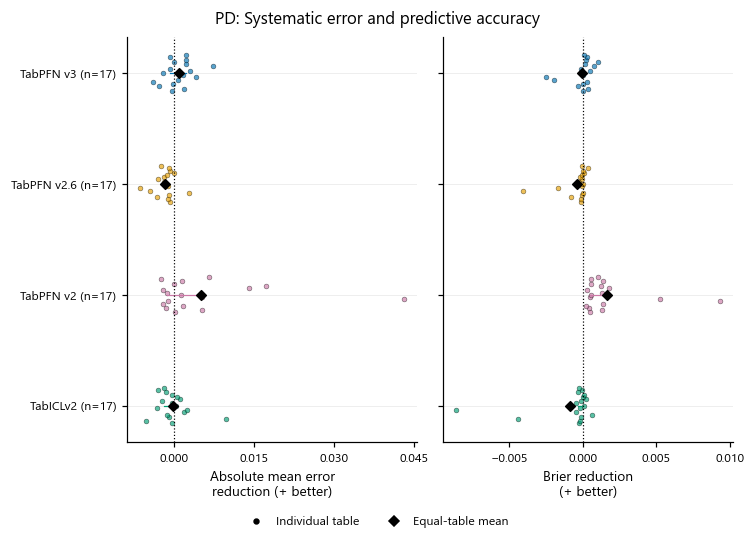

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [6]:
cp.show(sink, dg.plot_calibration_overview(run), track=run.track)
prediction_values, prediction_coverage = pred.analyze(run, reference=True)
report.table('Saved prediction coverage: fixed reference', prediction_coverage)
report.table('Paired per-table prediction diagnostics: fixed reference', prediction_values)
cp.show(sink, pred.plot_diagnostics(prediction_values, TRACK, coverage=prediction_coverage), track=TRACK)
report.add('5. Probability quality and prediction shifts', 'Brier score combines discrimination and calibration; ECE depends on its bins. The calibration overview compares the same tables across raw, Platt and isotonic scores; threshold-dependent F1 and ranking PR-AUC are included in the fixed-reference metric table.' + '\n' + pred.NOTE)

## 6. Fixed-context monitors, controls and cost

Monitoring uses fixed contexts during training and is distinct from the final five-fold benchmark above. Plot score change against learning rate, so both axes communicate a CPT choice or its effect. Separate legend boxes define learning rate, anchoring and update scope. Classical controls contextualize predictive performance; cost remains a compact table.

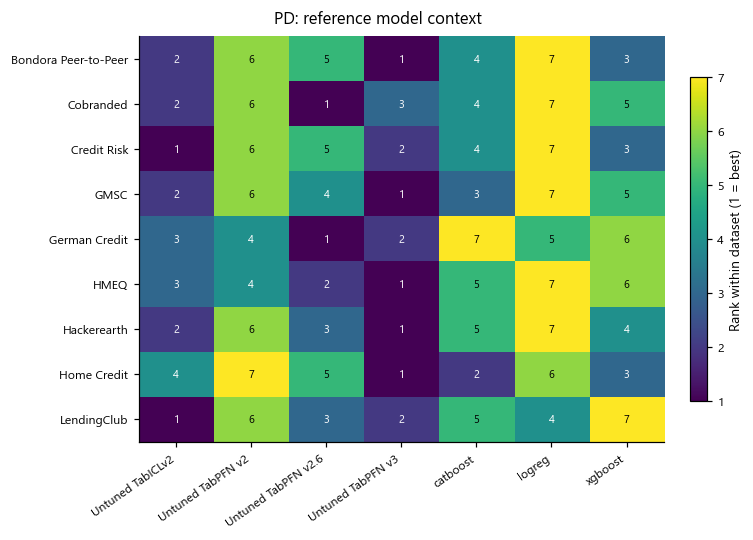

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

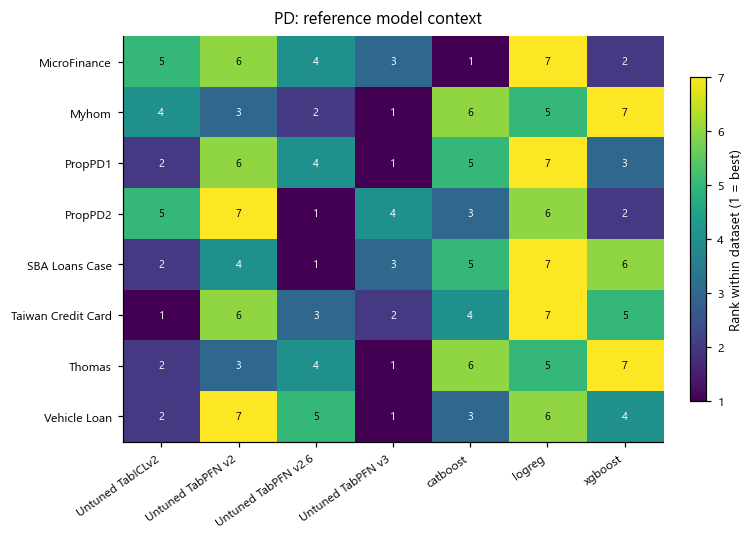

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,5880.051329,5388.954923,6227.217700,32,0.588005,0.538895,0.622722,32,27.1190,...,168231937,195157151,32,27552250.0,27552250,27552250,32,0.003687,0.001127,0.028629
"('TabICLv2', True)",32,5641.459922,5191.705577,5953.787302,32,0.564146,0.519171,0.595379,32,26.7075,...,168231937,195157151,32,1818106.0,1818106,1818106,32,0.006402,0.001463,0.042363
"('TabPFN v2', False)",32,4989.562487,4558.125119,5434.754171,32,0.498956,0.455813,0.543475,32,181.0705,...,74887937,84373151,32,7244554.0,7244554,7244554,32,0.004249,0.001053,0.028788
"('TabPFN v2', True)",32,4818.276219,4399.349810,5211.900758,32,0.481828,0.439935,0.521190,32,108.1805,...,74887937,84373151,32,166666.0,166666,166666,32,0.006800,0.001252,0.078394
"('TabPFN v2.6', False)",32,4264.081141,3931.728692,4570.578204,32,0.426408,0.393173,0.457058,32,128.4200,...,80721937,91297151,32,10732042.0,10732042,10732042,32,0.003833,0.000877,0.040765
"('TabPFN v2.6', True)",32,3799.214932,3556.330243,4103.147097,32,0.379921,0.355633,0.410315,32,80.4470,...,80721937,91297151,32,101386.0,101386,101386,32,0.001670,0.000229,0.015853
"('TabPFN v3', False)",32,5222.860977,4837.436067,5610.246155,32,0.522286,0.483744,0.561025,32,121.0455,...,168231937,195157151,32,53153136.0,53153136,53153136,32,0.006299,0.001484,0.052170
"('TabPFN v3', True)",32,4818.272543,4506.762127,5040.165402,32,0.481827,0.450676,0.504017,32,109.9990,...,168231937,195157151,32,1795440.0,1795440,1795440,32,0.006421,0.001305,0.037843


In [7]:
cp.show(sink, cp.plot_control_context(run), track=TRACK)
report.table('Completed-trial computational cost', pub.cost_summary(run))
report.add('6. Fixed-context monitors, controls and cost', 'Monitor changes pair each excluded credit table with its own update-zero score, then average tables equally. Monitor and final benchmark results answer related but distinct measurement questions. One main training seed and overlapping adaptation corpora limit independence claims.')

## Complete text summary

Every displayed value, table and caption, in section order. Detailed table effects remain available even where compact figures replace repeated panels.

In [8]:
print(report.summary(sink))

Experiment 1: PD outcomes and evaluation

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.

1. Evidence and benchmark eligibility
Run cpt_main_v5; PD; 256 planned trials; target 10,000 successful updates.
status
OK    256
1536 trajectory records; 11715 benchmark fold records.
PENDING means no recorded outcome; it can include running or queued work. This is not live scheduler state.

Table: Available evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project traj